In [7]:
import os
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
from implementations import (
    least_squares,
    ridge_regression,
    mean_squared_error_gd,
    mean_squared_error_sgd,
    logistic_regression,
    reg_logistic_regression,
)
from utils import (
    load_preprocess,
    build_k_indices,
    threshold_curve,
    f1_score,
    predict,
    step_size,
    weighted_reg_logistic_regression,
)
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")

In [ ]:
QUICK = False
k = 5  
MAX_ITERS = 1000  
SGD_ITERS = 100_000  
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
POS_WEIGHTS = [1.5, 2, 3]
POS_WEIGHTS = [2, 5, 10]  # how much more a positive sample counts (weighted logistic)

os.makedirs("results", exist_ok=True)
np.random.seed(0) 

## Loading Data 

In [18]:
tx, _, y, _, features = load_preprocess()
if QUICK:
    keep = np.random.default_rng(0).choice(len(y), min(50_000, len(y)), replace=False)
    tx, y = tx[keep], y[keep]
y01 = (y == 1).astype(float)  # logistic regression needs labels 0/1
N, D = tx.shape
k_indices = build_k_indices(y, K, seed=1)
w0 = np.zeros(D)
gamma_mse = step_size(tx, "mse")
gamma_sgd = 0.1 / np.mean(np.sum(tx**2, axis=1))  # one sample's curvature is ||x_n||^2
print(f"N={N}  D={D}  positives={y01.mean():.1%}  quick mode: {QUICK}")

N=328135  D=249  positives=8.8%  quick mode: False


In [19]:
print(gamma_mse, np.isfinite(gamma_mse))
print(np.isfinite(tx).all(), np.abs(tx).max())

0.08982340871141441 True
True 5.0


## Cross-validation 

In [20]:
def cross_validation(y, y01, tx, k_indices, k, train):
    """Train on all folds except the k-th one (same split as lab 4).

    Args:
        y, y01:     labels in {-1, 1} and {0, 1}, shape=(N,)
        tx:         data matrix, shape=(N, D)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold is the validation fold
        train:      function train(y_pm, y01, tx) -> w

    Returns:
        w, te_indice, tr_indice: the weights and the validation / training row indices
    """
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)].reshape(-1)
    w = train(y[tr_indice], y01[tr_indice], tx[tr_indice])
    return w, te_indice, tr_indice


def cross_validate(model, param, train):
    """Run cross_validation() for every fold, tune the threshold and summarize."""
    start = time.time()
    oof_scores = np.full(N, np.nan)  # each row scored by the model that did not see it
    fitted = []
    for k in range(K):
        try:
            w, te_indice, tr_indice = cross_validation(y, y01, tx, k_indices, k, train)
        except np.linalg.LinAlgError as err:  # e.g. least squares with a singular X^T X
            print(f"{model:<22} {param:<16} failed: {err}")
            return None
        oof_scores[te_indice] = tx[te_indice] @ w
        fitted.append((te_indice, tr_indice, w))

    used = k_indices.reshape(-1)  # rows in some fold (build_k_indices may leave out N % K rows)
    thresholds, f1s = threshold_curve(oof_scores[used], y[used])
    t = thresholds[np.argmax(f1s)]
    val_f1 = [f1_score(y[te], predict(oof_scores[te], t)) for te, _, _ in fitted]
    val_acc = [np.mean(predict(oof_scores[te], t) == y[te]) for te, _, _ in fitted]
    train_f1 = [f1_score(y[tr], predict(tx[tr] @ w, t)) for _, tr, w in fitted]

    r = dict(
        model=model,
        param=param,
        f1=np.mean(val_f1),
        f1_std=np.std(val_f1),
        acc=np.mean(val_acc),
        acc_std=np.std(val_acc),
        train_f1=np.mean(train_f1),
        threshold=t,
        curve=(thresholds, f1s),
    )
    print(
        f"{model:<22} {param:<16} F1 {r['f1']:.4f} ± {r['f1_std']:.4f}   acc {r['acc']:.4f}   "
        f"train F1 {r['train_f1']:.4f}   ({time.time() - start:.0f}s)"
    )
    return r

results = []

def run(model, param, train):
    """Cross-validate one setting and store its result."""
    r = cross_validate(model, param, train)
    if r is not None:
        results.append(r)
    return r

## Running different models

In [21]:
# Least squares and ridge regression for every lambda
run("least squares", "-", lambda yp, y01_, x: least_squares(yp, x)[0])
for lam in LAMBDAS:
    run("ridge", f"lambda={lam:g}", lambda yp, y01_, x, lam=lam: ridge_regression(yp, x, lam)[0])

least squares          -                F1 0.4135 ± 0.0037   acc 0.8544   train F1 0.4148   (3s)
ridge                  lambda=1e-06     F1 0.4135 ± 0.0036   acc 0.8544   train F1 0.4148   (3s)
ridge                  lambda=1e-05     F1 0.4135 ± 0.0036   acc 0.8544   train F1 0.4148   (3s)
ridge                  lambda=0.0001    F1 0.4135 ± 0.0037   acc 0.8544   train F1 0.4147   (3s)
ridge                  lambda=0.0003    F1 0.4135 ± 0.0038   acc 0.8544   train F1 0.4147   (3s)
ridge                  lambda=0.001     F1 0.4132 ± 0.0041   acc 0.8572   train F1 0.4151   (3s)
ridge                  lambda=0.003     F1 0.4132 ± 0.0047   acc 0.8660   train F1 0.4150   (3s)
ridge                  lambda=0.01      F1 0.4129 ± 0.0036   acc 0.8630   train F1 0.4141   (4s)
ridge                  lambda=0.1       F1 0.4078 ± 0.0031   acc 0.8677   train F1 0.4084   (4s)


In [22]:
# Linear regression with gradient descent and stochastic gradient descent
run(
    "MSE GD",
    f"gamma={gamma_mse:.3g}",
    lambda yp, y01_, x: mean_squared_error_gd(yp, x, w0, MAX_ITERS, gamma_mse)[0],
)
run(
    "MSE SGD",
    f"gamma={gamma_sgd:.3g}",
    lambda yp, y01_, x: mean_squared_error_sgd(yp, x, w0, SGD_ITERS, gamma_sgd)[0],
)

MSE GD                 gamma=0.0898     F1 0.4130 ± 0.0047   acc 0.8689   train F1 0.4151   (74s)
MSE SGD                gamma=0.0007     F1 0.3760 ± 0.0094   acc 0.8451   train F1 0.3779   (4s)


{'model': 'MSE SGD',
 'param': 'gamma=0.0007',
 'f1': np.float64(0.3760169297803507),
 'f1_std': np.float64(0.00943801721761348),
 'acc': np.float64(0.8451277675347036),
 'acc_std': np.float64(0.007890600241493725),
 'train_f1': np.float64(0.377919805751302),
 'threshold': np.float64(-0.5810099754234613),
 'curve': (array([-0.87617047, -0.87328359, -0.87026487, -0.86728132, -0.86429131,
         -0.86117227, -0.85815878, -0.85512839, -0.85210306, -0.84891946,
         -0.84592266, -0.84282504, -0.83963655, -0.83634408, -0.83297457,
         -0.82961777, -0.82631489, -0.82300796, -0.81967108, -0.81624119,
         -0.81279489, -0.80920991, -0.80576857, -0.80229255, -0.79875665,
         -0.79521428, -0.79155523, -0.78791481, -0.78413039, -0.78043327,
         -0.77659737, -0.7727844 , -0.76895997, -0.76517492, -0.76123693,
         -0.75730597, -0.75318169, -0.74914865, -0.74503424, -0.74088869,
         -0.73665295, -0.73222606, -0.72781027, -0.7233687 , -0.71871285,
         -0.713991

In [24]:
# Logistic regression and regularized logistic regression for every lambda
g = step_size(tx, "logistic")
run("logistic", "-", lambda yp, y01_, x, g=g: logistic_regression(y01_, x, w0, MAX_ITERS, g)[0])

for lam in LAMBDAS:
    g = step_size(tx, "logistic", lam)
    run(
        "reg logistic",
        f"lambda={lam:g}",
        lambda yp, y01_, x, lam=lam, g=g: reg_logistic_regression(y01_, x, lam, w0, MAX_ITERS, g)[0],
    )

logistic               -                F1 0.4258 ± 0.0032   acc 0.8689   train F1 0.4279   (124s)
reg logistic           lambda=1e-06     F1 0.4258 ± 0.0031   acc 0.8689   train F1 0.4279   (119s)
reg logistic           lambda=1e-05     F1 0.4258 ± 0.0031   acc 0.8689   train F1 0.4279   (117s)
reg logistic           lambda=0.0001    F1 0.4260 ± 0.0031   acc 0.8690   train F1 0.4278   (116s)
reg logistic           lambda=0.0003    F1 0.4258 ± 0.0033   acc 0.8689   train F1 0.4278   (114s)
reg logistic           lambda=0.001     F1 0.4258 ± 0.0037   acc 0.8689   train F1 0.4279   (114s)
reg logistic           lambda=0.003     F1 0.4238 ± 0.0027   acc 0.8656   train F1 0.4256   (116s)
reg logistic           lambda=0.01      F1 0.4194 ± 0.0028   acc 0.8645   train F1 0.4203   (116s)
reg logistic           lambda=0.1       F1 0.3982 ± 0.0022   acc 0.8566   train F1 0.3983   (114s)


In [26]:
# Weighted logistic regression for every lambda and positive weight
# uses best lambda from regularized logistic regression
best_reg = max((r for r in results if r["model"] == "reg logistic"), key=lambda r: r["f1"])
best_lam = float(best_reg["param"].split("=")[1])

for pw in POS_WEIGHTS:
    g = step_size(tx, "logistic", best_lam, y01, pw)
    run(
        "weighted reg logistic",
        f"lambda={best_lam:g} pw={pw}",
        lambda yp, y01_, x, pw=pw, g=g: weighted_reg_logistic_regression(
            y01_, x, best_lam, w0, MAX_ITERS, g, pw
        ),
    )

weighted reg logistic  lambda=0.0001 pw=2 F1 0.4266 ± 0.0030   acc 0.8691   train F1 0.4278   (78s)
weighted reg logistic  lambda=0.0001 pw=5 F1 0.4260 ± 0.0031   acc 0.8690   train F1 0.4278   (76s)
weighted reg logistic  lambda=0.0001 pw=10 F1 0.4247 ± 0.0023   acc 0.8658   train F1 0.4263   (78s)


## Results

In [28]:
with open("results/cv_results.csv", "w") as f:
    f.write("model,param,val_f1,val_f1_std,val_acc,val_acc_std,train_f1,threshold\n")
    for r in results:
        f.write(
            f"{r['model']},{r['param']},{r['f1']:.4f},{r['f1_std']:.4f},{r['acc']:.4f},"
            f"{r['acc_std']:.4f},{r['train_f1']:.4f},{r['threshold']:.6f}\n"
        )

print(f"{'model':<22} {'param':<16} {'val F1':>16} {'val acc':>8} {'train F1':>9}")
for r in sorted(results, key=lambda r: -r["f1"]):
    print(
        f"{r['model']:<22} {r['param']:<16} {r['f1']:.4f} ± {r['f1_std']:.4f} "
        f"{r['acc']:>8.4f} {r['train_f1']:>9.4f}"
    )

model                  param                      val F1  val acc  train F1
weighted reg logistic  lambda=0.0001 pw=2 0.4266 ± 0.0030   0.8691    0.4278
reg logistic           lambda=0.0001    0.4260 ± 0.0031   0.8690    0.4278
weighted reg logistic  lambda=0.0001 pw=5 0.4260 ± 0.0031   0.8690    0.4278
reg logistic           lambda=1e-06     0.4258 ± 0.0031   0.8689    0.4279
logistic               -                0.4258 ± 0.0032   0.8689    0.4279
reg logistic           lambda=1e-05     0.4258 ± 0.0031   0.8689    0.4279
reg logistic           lambda=0.001     0.4258 ± 0.0037   0.8689    0.4279
reg logistic           lambda=0.0003    0.4258 ± 0.0033   0.8689    0.4278
weighted reg logistic  lambda=0.0001 pw=10 0.4247 ± 0.0023   0.8658    0.4263
reg logistic           lambda=0.003     0.4238 ± 0.0027   0.8656    0.4256
reg logistic           lambda=0.01      0.4194 ± 0.0028   0.8645    0.4203
ridge                  lambda=0.0003    0.4135 ± 0.0038   0.8544    0.4147
ridge            

## Figure: model comparison

Best hyperparameters of each model, with the tuned threshold.

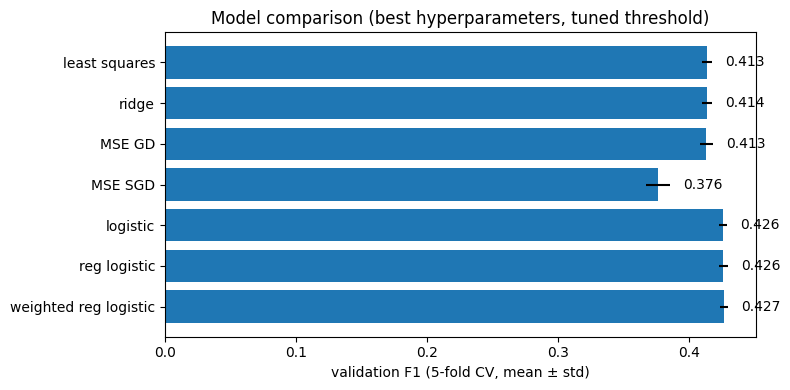

In [29]:
families = list(dict.fromkeys(r["model"] for r in results))
bests = [max((r for r in results if r["model"] == m), key=lambda r: r["f1"]) for m in families]

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(
    families[::-1],
    [r["f1"] for r in bests[::-1]],
    xerr=[r["f1_std"] for r in bests[::-1]],
    color="tab:blue",
)
for i, r in enumerate(bests[::-1]):
    ax.text(r["f1"] + r["f1_std"] + 0.01, i, f"{r['f1']:.3f}", va="center")
ax.set_xlabel(f"validation F1 ({K}-fold CV, mean ± std)")
ax.set_title("Model comparison (best hyperparameters, tuned threshold)")
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=150)
plt.show()

## Figure: F1 vs $\lambda$ (bias–variance)

- **Train much higher than validation**: overfitting (small $\lambda$).
- **Both dropping**: underfitting (large $\lambda$).

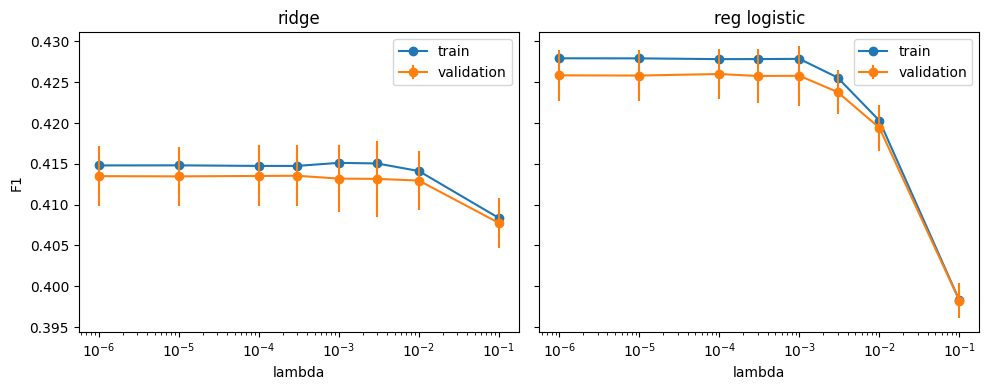

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, model in zip(axes, ["ridge", "reg logistic"]):
    rs = [r for r in results if r["model"] == model]
    lams = [float(r["param"].split("=")[1]) for r in rs]
    ax.semilogx(lams, [r["train_f1"] for r in rs], "o-", label="train")
    ax.errorbar(lams, [r["f1"] for r in rs], yerr=[r["f1_std"] for r in rs], fmt="o-", label="validation")
    ax.set_xlabel("lambda")
    ax.set_title(model)
    ax.legend()
axes[0].set_ylabel("F1")
fig.tight_layout()
fig.savefig("results/f1_vs_lambda.png", dpi=150)
plt.show()

## Figure: F1 vs decision threshold (best model)

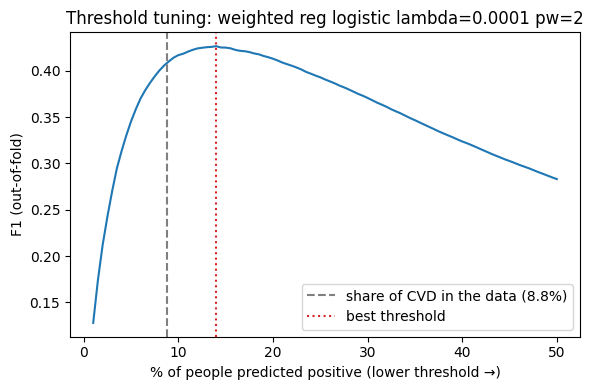

In [31]:
best = max(results, key=lambda r: r["f1"])
thresholds, f1s = best["curve"]
share_positive = 1 - np.linspace(0.50, 0.99, 99)  # fraction of people predicted positive per threshold

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(share_positive * 100, f1s)
ax.axvline(y01.mean() * 100, color="gray", linestyle="--", label=f"share of CVD in the data ({y01.mean():.1%})")
ax.axvline(share_positive[np.argmax(f1s)] * 100, color="tab:red", linestyle=":", label="best threshold")
ax.set_xlabel("% of people predicted positive (lower threshold →)")
ax.set_ylabel("F1 (out-of-fold)")
ax.set_title(f"Threshold tuning: {best['model']} {best['param']}")
ax.legend()
fig.tight_layout()
fig.savefig("results/f1_vs_threshold.png", dpi=150)
plt.show()

## feature-importance

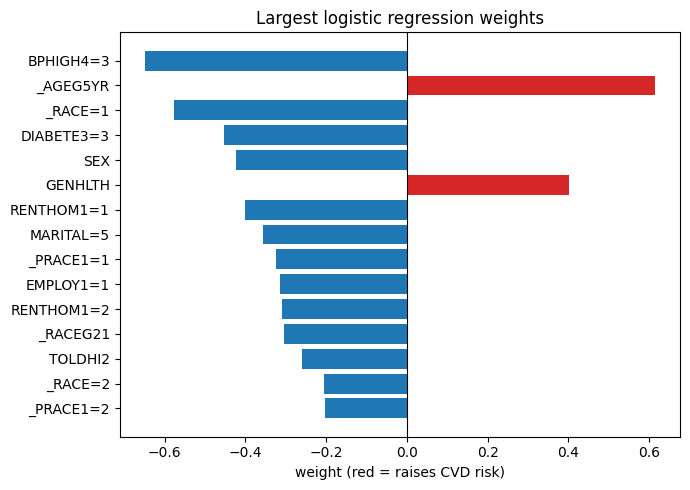

In [32]:
# train the best regularized logistic model on all data and show its largest weights
w_full, _ = reg_logistic_regression(y01, tx, best_lam, w0, MAX_ITERS, step_size(tx, "logistic", best_lam))
top = np.argsort(-np.abs(w_full[1:]))[:15] + 1  # skip the bias (index 0)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(np.array(features)[top][::-1], w_full[top][::-1],
        color=np.where(w_full[top][::-1] > 0, "tab:red", "tab:blue"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("weight (red = raises CVD risk)")
ax.set_title("Largest logistic regression weights")
fig.tight_layout()
fig.savefig("results/top_weights.png", dpi=150)
plt.show()

## Settings for `run.py`

Only copy these from a run with `QUICK = False`.

In [33]:
print(f"best: {best['model']} {best['param']}  F1 {best['f1']:.4f} ± {best['f1_std']:.4f}")
if QUICK:
    print("(quick mode: set QUICK = False and re-run before copying settings into run.py)")
settings = dict(p.split("=") for p in best["param"].split() if "=" in p)
print("\nsettings to copy into run.py:")
print(f'MODEL = "{best["model"]}"')
print(f"LAMBDA = {settings.get('lambda', '0')}")
print(f"POS_WEIGHT = {settings.get('pw', '1')}")
print(f"THRESHOLD = {best['threshold']:.6f}")

best: weighted reg logistic lambda=0.0001 pw=2  F1 0.4266 ± 0.0030

settings to copy into run.py:
MODEL = "weighted reg logistic"
LAMBDA = 0.0001
POS_WEIGHT = 2
THRESHOLD = -0.721576
